# Cartographie des communes accueillant des établissements hospitaliers

## Objectif

L'objectif est de proposer une analyse de la présence des hôpitaux à l'échelle communale, au regard d'indicateurs comme le revenu médian ou encore la densité de population.

Tout d'abord nous allons réaliser une carte interactive de la France métropolitaine permettant de visualiser les communes accueillant au moins un établissement hospitalier. Les communes concernées sont identifiées à partir de la base de données hospitalières précédemment enrichie avec les codes INSEE communaux. (fichier geo_to_city.ipynb). La carte représentera également le revenu médian des communes, à partir d'une seconde base de données (filosofi et la base df_final qui en découle), afin de mettre en regard la localisation des établissements hospitaliers et les caractéristiques socio-économiques des territoires.

## Sources des données

- Base de données hospitalières : BASE_loc_hopitaux.csv
- Données géographiques : Cartiflette
- Données de revenus médians : df_final.xlsx

## Limites

Cette première visualisation est indicative.

Elle ne tient notamment pas compte :
- de la densité de population ;
- des axes et temps de transport ;
- de l'accessibilité réelle des établissements hospitaliers ;
- des besoins de santé des populations.

Les territoires ultramarins ne sont pas intégrés à la base hospitalière initiale et sont donc exclus de la représentation.

## 1. Importation des bibliothèques

Les bibliothèques utilisées permettent de manipuler les données tabulaires et géographiques, de traiter les géométries et de construire
une carte interactive.

In [1]:
%pip install folium
%pip install pandas
%pip install geopandas
%pip install --upgrade cartiflette
%pip install duckdb==1.5.5
%pip install ipywidgets #nécessaire pour cartiflette dans les notebooks
%pip install matplotlib
%pip install openpyxl


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note

In [ ]:
import folium
import geopandas as gpd
import pandas as pd
from pathlib import Path
from shapely.ops import unary_union
from shapely.wkt import loads
from cartiflette import carti_download
import branca.colormap as cm
import matplotlib.pyplot as plt
import openpyxl 

## 2. Importation des données hospitalières

Nous importons la base de données hospitalières produite lors de l'étape précédente. Cette base contient notamment les codes INSEE des communes d'appartenance des établissements ainsi que les coordonnées géographiques des hôpitaux.

In [3]:
RACINE = Path.cwd()

hop = pd.read_csv(RACINE / "data/processed/BASE_loc_hopitaux.csv",dtype={"COM_INSEE": str})
hop

,Unnamed: 0,name,geometry,INSEE_DEP,COM_INSEE,NOM,STATUT,POPULATION,AREA,NOM_REGIO
0,0,Établissement Public de Santé de Fresnes,POINT (2.3204394720897508 48.765358697049884),94.0,94034,Fresnes,Commune simple,28710.0,metropole,Île-de-France
1,1,Centre Hospitalier du Penthièvre & du Poudouvre,POINT (-2.9150206382368027 48.40770371497279),22.0,22262,Quintin,Commune simple,2867.0,metropole,Bretagne
2,2,Clinique Pech du Soleil,POINT (3.248666063007142 43.36662523139691),34.0,34037,Boujan-sur-Libron,Commune simple,3367.0,metropole,Occitanie
3,3,Hôpital Bichat-Claude Bernard,POINT (2.3319566083744125 48.898862750459095),75.0,75056,Paris,Capitale d'état,2165423.0,metropole,Île-de-France
4,4,Unité de Santé Mentale pour Adultes,POINT (1.8845839251441407 50.957569303600344),62.0,62193,Calais,Sous-préfecture,72509.0,metropole,Hauts-de-France
...,...,...,...,...,...,...,...,...,...,...
2501,2501,NaN,POINT (-1.1314808503000995 44.75322679365934),33.0,33011,Arès,Commune simple,6381.0,metropole,Nouvelle-Aquitaine
2502,2502,Clinique Rougemont,POINT (0.1562301168755829 48.020178940659164),72.0,72181,Le Mans,Préfecture,143847.0,metropole,Pays de la Loire
2503,2503,Clinique de l'Étang de l'Olivier,POINT (4.992070528967937 43.508062455621534),13.0,13047,Istres,Sous-préfecture,43626.0,metropole,Provence-Alpes-Côte d'Azur
2504,2504,Institut Paoli-Calmettes,POINT (5.4099134006247285 43.26235297670494),13.0,13055,Marseille,Préfecture de région,870731.0,metropole,Provence-Alpes-Côte d'Azur


## 3. Téléchargement des fonds de carte

Nous utilisons Cartiflette pour récupérer les contours géographiques des communes et des régions françaises.

Deux informations sont récupérées :

- Les contours communaux, qui permettent d'identifier et de représenter les communes accueillant des hôpitaux.
- Les contours régionaux, qui servent de fond de carte à la représentation.

La simplification géométrique est fixée à 50 afin de limiter le poids des données et de faciliter l'affichage de la carte interactive.

In [4]:

print("Téléchargement des communes...")
gdf_communes = carti_download(
    values="France",
    borders="COMMUNE",
    filter_by="FRANCE_ENTIERE_DROM_RAPPROCHES", #On a fait le choix de garder cette option de cartiflette même s'il n'y a pas de données pour les DROM car elle permet d'avoir l'Île-de-France affichée à part.
    simplification=50,
    crs=4326
)

print("Téléchargement du contour France...")
gdf_france = carti_download(
    values="France",
    borders="REGION",
    filter_by="FRANCE_ENTIERE_DROM_RAPPROCHES",
    simplification=50,
    crs=4326
)

print("Téléchargement complété")

Téléchargement des communes...
Téléchargement du contour France...
Téléchargement complété


## 4. Identification des communes accueillant des hôpitaux

L'objectif est d'identifier les communes dans lesquelles se situe au moins un établissement hospitalier.

Deux méthodes sont mobilisées :

- Pour les communes hors Corse : une correspondance directe est réalisée entre les codes INSEE des communes et ceux présents dans la base hospitalière.
- Pour la Corse : une jointure spatiale est réalisée à partir des coordonnées géographiques des établissements.

Ce traitement particulier est nécessaire car les codes INSEE corses ne peuvent pas être exploités de la même manière dans la base initiale. (les codes insee commencent par 2A/2B)

Il faut aussi exclure les fonds de carte des DROM.

In [5]:
# Retrait des DROM
#En passant par les communes : 
gdf_communes = gdf_communes[~gdf_communes["INSEE_COM"].str.startswith("97")].copy()

# On retire les contours des régions d'outre-mer (codes 01, 02, 03, 04, 06) : 
regions_drom = ["01", "02", "03", "04", "06"]
gdf_france = gdf_france[~gdf_france["INSEE_REG"].isin(regions_drom)].copy()

In [6]:
#Traitement des communes hors Corse : correspondance directe par code INSEE
condition_insee = gdf_communes["INSEE_COM"].isin(hop["COM_INSEE"])

In [7]:
# Cas de la Corse : repérage des communes contenant un point GPS d'hôpital
hop_corse = hop[hop["NOM_REGIO"] == "Corse"].copy()

if not hop_corse.empty:
    # Conversion du texte WKT en géométrie GeoPandas (CRS 4326)
    hop_corse["geometry"] = hop_corse["geometry"].apply(loads)
    gdf_hop_corse = gpd.GeoDataFrame(hop_corse, geometry="geometry", crs=4326)

    # On filtre Cartiflette sur la Corse via les codes INSEE commençant par 2A ou 2B
    gdf_communes_corse = gdf_communes[gdf_communes["INSEE_COM"].str.startswith(("2A", "2B"))]

    # Jointure spatiale : trouve dans quelle commune tombe chaque hôpital corse
    communes_corse_avec_hop = gpd.sjoin(
        gdf_communes_corse, 
        gdf_hop_corse, 
        how="inner", 
        predicate="contains"
    )
    
    # Liste des vrais codes INSEE (2A... / 2B...) des communes corses ayant un hôpital
    codes_insee_corse_hop = communes_corse_avec_hop["INSEE_COM"].unique()
    condition_corse = gdf_communes["INSEE_COM"].isin(codes_insee_corse_hop)
else:
    condition_corse = pd.Series(False, index=gdf_communes.index)

In [8]:
# Sélection finale : uniquement les communes qui ont un hôpital (dont communes corses)

gdf_selection = gdf_communes[
    condition_corse | condition_insee
].copy()

# Fusion des géométries uniquement pour tracer le contour extérieur global
union_communes = unary_union(gdf_selection.geometry)

gdf_selection_fusionnee = gpd.GeoDataFrame(
    geometry=[union_communes],
    crs=gdf_communes.crs
)

## 5. Préparation du fond de carte et des revenus médians

Nous créons une carte interactive avec Folium, centrée sur la France. La représentation repose sur une coloration des communes en fonction
de leur revenu médian. Les données de revenus sont importées depuis le fichier df_final.xlsx. Elles sont ensuite associées aux communes à partir de leur code INSEE.

Une échelle de couleurs allant du bleu au rouge est utilisée : les valeurs faibles sont représentées en bleu et les valeurs élevées
en rouge. Afin de limiter l'influence des valeurs extrêmes, les bornes de l'échelle sont définies à partir des 10e et 90e centiles.

In [9]:
#Création de la carte

m = folium.Map(location=[46.603354, 1.888334], zoom_start=6, tiles=None)

In [10]:
#Importation des revenus

df_final = pd.read_excel(RACINE / "data/processed/df_final.xlsx", dtype={"COM_INSEE": str})


# Nettoyage au cas où il y aurait des valeurs manquantes dans la colonne revenu
df_revenus_valides = df_final.dropna(subset=["COM_INSEE", "revenu_median"])

# Création du dictionnaire {code_insee: revenu_median}
dict_revenus = df_revenus_valides.set_index("COM_INSEE")["revenu_median"].to_dict()




In [ ]:
#Définition de l'échelle de couleur : 
# On borne l'échelle entre le 10e et le 90e centile pour éviter que les extrêmes n'écrasent les couleurs (l'échelle est construite à partir de toutes les villes pas juste les villes où il y a un hôpital)
revenu_min = df_revenus_valides["revenu_median"].quantile(0.10)
revenu_max = df_revenus_valides["revenu_median"].quantile(0.90)

colormap = cm.LinearColormap(
    colors=["blue", "white", "red"], 
    vmin=revenu_min,
    vmax=revenu_max,
    caption="Revenu médian par ville (€) - échelle 10e-90e centiles"
)


## 6. Définition des fonctions de représentation cartographique

Trois fonctions permettent de définir l'apparence des différentes couches de la carte :

- Le fond de carte représentant les contours régionaux en blanc.
- Les communes accueillant des hôpitaux, colorées selon leur revenu médian.
- Le contour extérieur des zones sélectionnées, représenté en gris foncé.

Lorsque le revenu médian d'une commune n'est pas renseigné, une couleur grise est utilisée.

In [13]:
# Fonctions de style

def style_france_blanc(feature):
    return {
        "fillColor": "#FFFFFF",
        "fillOpacity": 1.0,
        "color": "#D3D3D3",
        "weight": 1
    }


def style_commune_revenu(feature):
    # Cartiflette stocke le code commune sous "INSEE_COM"
    code_insee = feature["properties"].get("INSEE_COM")
    revenu = dict_revenus.get(code_insee)

    if revenu is not None and pd.notna(revenu):
        couleur = colormap(revenu)
        opacite = 0.75
    else:
        # Couleur grise si la commune n'a pas de revenu renseigné
        couleur = "#E0E0E0"
        opacite = 1

    return {
        "fillColor": couleur,
        "fillOpacity": opacite,
        "color": couleur,
        "weight": 0.5
    }


def style_contour_exterieur(feature):
    return {
        "fill": False,
        "color": "#333333",
        "weight": 1.5
    }

## 7. Construction de la carte et ajout des couches géographiques

Les différentes couches sont ajoutées successivement à la carte :

1. Le fond régional de la France.
2. Les communes accueillant des hôpitaux, colorées selon leur revenu médian.
3. Le contour extérieur des communes sélectionnées.
4. La légende permettant d'interpréter l'échelle de couleurs.

In [14]:
# Fond France
folium.GeoJson(
    gdf_france,
    style_function=style_france_blanc,
    name="Fond France"
).add_to(m)

# Couche des villes colorées individuellement selon le revenu médian
folium.GeoJson(
    gdf_selection,
    style_function=style_commune_revenu,
    name="Revenu médian des communes"
).add_to(m)

# Contour global autour des zones fusionnées
folium.GeoJson(
    gdf_selection_fusionnee,
    style_function=style_contour_exterieur,
    name="Contours des zones"
).add_to(m)

# Ajout de la légende des couleurs sur la carte
colormap.add_to(m)

## 8. Localisation des communes accueillant des établissements hospitaliers

En complément de la représentation des communes, des marqueurs permettent d'identifier les communes accueillant au moins un
établissement hospitalier.

Pour les communes hors Corse, les marqueurs sont positionnés à partir d'un point représentatif de la géométrie communale (`representative_point`). Ils indiquent donc la présence d'au moins un hôpital dans la commune, sans correspondre à sa localisation géographique exacte.

Pour la Corse, les coordonnées géographiques réelles des établissements hospitaliers sont directement utilisées.

La couleur des marqueurs reprend celle associée au revenu médian de la commune. Lorsque cette information est absente, une couleur grise
est utilisée.

Chaque marqueur comporte une fenêtre contextuelle indiquant le nom de la commune ou de l'établissement et, lorsque disponible, le revenu médian.

In [15]:
dict_noms = pd.Series(
    gdf_communes.NOM.values,
    index=gdf_communes.INSEE_COM
).to_dict()

for index, row in hop.iterrows():

    est_corse = False

    if "NOM_REGIO" in row and row["NOM_REGIO"] == "Corse":
        est_corse = True

    if est_corse:

        # 1. On transforme le texte WKT en vraie géométrie Shapely
        wkt_geometry = row["geometry"]
        point_geom = loads(wkt_geometry)

        # 2. On extrait directement X et Y de cet objet géométrique
        lat = point_geom.y
        lon = point_geom.x

        nom_affichage = row.get(
            "nom",
            row.get("NOM", "Hôpital (Corse)")
        )

    else:

        code_insee = row["COM_INSEE"]
        commune_geo = gdf_communes[
            gdf_communes["INSEE_COM"] == code_insee
        ]

        if not commune_geo.empty:
            point_centre = commune_geo.geometry.iloc[0].representative_point()
            lat, lon = point_centre.y, point_centre.x
            nom_affichage = dict_noms.get(
                code_insee,
                "Commune hôpital"
            )
        else:
            continue

    # Dessin du marqueur sur la carte
    revenu = dict_revenus.get(code_insee)

    couleur_point = (
        colormap(revenu)
        if (revenu is not None and pd.notna(revenu))
        else "#808080"
    )

    folium.CircleMarker(
        location=[lat, lon],
        radius=4,
        color="#333333",
        weight=1,
        fill=True,
        fill_color=couleur_point,
        fill_opacity=0.9,
        popup=f"{nom_affichage} ({int(revenu)} €)"
        if pd.notna(revenu)
        else nom_affichage,
    ).add_to(m)

## 9. Exportation de la carte interactive

La carte est exportée au format HTML afin de pouvoir être consultée dans un navigateur Internet.

Ainsi, la carte est interactive, comme le permet le package Folium.

In [16]:
m.save(
    RACINE / "data/processed/carte_france_villes_hop.html"
)

print("Fait ! La carte a été générée avec succès.")

Fait ! La carte a été générée avec succès.


## 10. Limites et précautions d'interprétation

Cette carte constitue une première représentation descriptive de la localisation des établissements hospitaliers.

Plusieurs limites doivent être prises en compte :

- Les territoires ultramarins ne sont pas représentés, car ils sont absents de la base hospitalière initiale.
- La présence d'un hôpital dans une commune ne renseigne pas sur le nombre d'habitants desservis.
- La représentation ne tient pas compte de la densité de population.
- Elle ne prend pas en considération les distances et les temps d'accès aux établissements.
- Le revenu médian est une caractéristique socio-économique communale et ne permet pas, à lui seul, de mesurer les besoins de santé.

Cette carte permet donc avant d'avoir une approche exploratoire visuelle de la présence des hôpitaux en France.

## 11. Analyse de la répartition des hôpitaux selon le revenu médian

Afin d'étudier le lien entre la localisation des établissements hospitalierset les caractéristiques socio-économiques des territoires, nous croisonsla base hospitalière avec les données de revenus médians communaux.

Les communes sont réparties en cinq classes de revenu médian, définiesà partir des quintiles de la distribution des revenus.

Nous calculons ensuite le nombre d'établissements hospitaliers présentsdans chacune de ces classes.

In [17]:
# Création des classes de revenu médian à partir des quintiles

df_final["classe_revenu"] = pd.qcut(
    df_final["revenu_median"],
    q=5,
    labels=[
        "Q1 - Revenus les plus faibles",
        "Q2",
        "Q3",
        "Q4",
        "Q5 - Revenus les plus élevés"
    ]
)

In [18]:
# Association du revenu médian à chaque hôpital via le code INSEE communal

hop_revenus = hop.merge(
    df_final[["COM_INSEE", "revenu_median", "classe_revenu"]],
    on="COM_INSEE",
    how="left"
)

In [19]:
# Comptage des établissements hospitaliers par classe de revenu

nombre_hopitaux_revenu = (
    hop_revenus
    .groupby("classe_revenu", observed=False)
    .size()
    .reset_index(name="Nombre d'hôpitaux")
)

display(nombre_hopitaux_revenu)

,classe_revenu,Nombre d'hôpitaux
0,Q1 - Revenus les plus faibles,1035
1,Q2,493
2,Q3,279
3,Q4,252
4,Q5 - Revenus les plus élevés,420


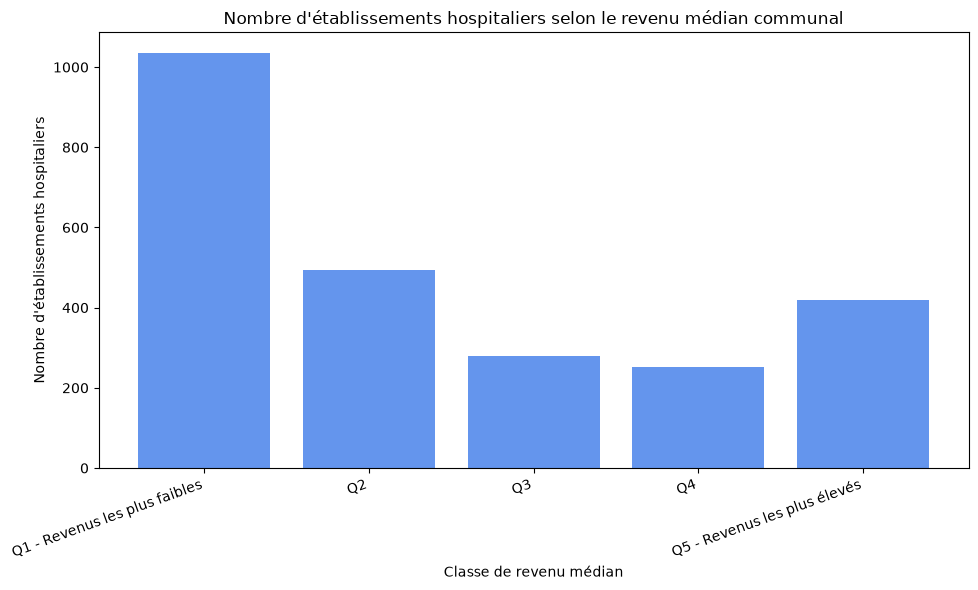

In [ ]:

plt.figure(figsize=(10, 6))

plt.bar(
    nombre_hopitaux_revenu["classe_revenu"].astype(str),
    nombre_hopitaux_revenu["Nombre d'hôpitaux"],
    color="#6495ED"
)

plt.title(
    "Nombre d'établissements hospitaliers selon le revenu médian communal"
)

plt.xlabel("Classe de revenu médian")
plt.ylabel("Nombre d'établissements hospitaliers")

plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

## 12. Analyse comparative de la population des communes

Nous cherchons à comparer la population moyenne des communes accueillant au moins un établissement hospitalier avec celle de l'ensemble des communes françaises métropolitaines.

Pour éviter les doubles comptes, chaque commune accueillant plusieurs établissements hospitaliers ne sera comptabilisée qu'une seule fois.

In [22]:
# On conserve une seule ligne par commune accueillant un hôpital

communes_hopitaux = hop.drop_duplicates(
    subset=["COM_INSEE"]
).copy()

# Calcul de la population moyenne
population_moyenne_hopitaux = communes_hopitaux["POPULATION"].mean()


# Calcul de la population médiane
population_mediane_hopitaux = communes_hopitaux["POPULATION"].median()

print(
    "Population moyenne des communes avec hôpital :",
    round(population_moyenne_hopitaux, 0),
    "habitants"
)

print(
    "Population médiane des communes avec hôpital :",
    round(population_mediane_hopitaux, 0),
    "habitants"
)

Population moyenne des communes avec hôpital : 21167.0 habitants
Population médiane des communes avec hôpital : 7964.0 habitants


Cette publication de l'INSEE *Plus d’une commune métropolitaine sur deux compte moins de 500 habitant* (https://www.insee.fr/fr/statistiques/1908488) montre qu'une commune métropolitaine sur deux compte moins de 500 habitants en 2015. Les villes acceuillant au moins un hôpital sont donc, et ce n'est pas surprenant, dotée d'une population médiane bien plus élevée que la médiane nationale, sous réserve que la population médiane nationale n'ai pas explosée entre 2015 et aujourd'hui. Une publication de 2023 va dans ce sens, *Structure de la population selon la taille des communes en 2023* (https://www.insee.fr/fr/statistiques/2012729?utm_source=chatgpt.com#tableau-TCRD_043_tab1_departements) en montrant que 25,3% des communes ont moins de 200 habitants et 71,8 entre 200 et 9 999 habitants. Si la médiane n'est pas communiquée, ces chiffres soutiennent l'idée qu'elle soit largement inférieur à 7 964. 
